In [ ]:
!pip install -q diffusers transformers accelerate safetensors gradio

In [ ]:
import torch
import gradio as gr
import time
import random
import os

from PIL import Image
from diffusers import StableDiffusionPipeline

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not detected. Generation will be much slower.")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
MODEL_ID = "runwayml/stable-diffusion-v1-5"

device = "cuda" if torch.cuda.is_available() else "cpu"

dtype = torch.float16 if device == "cuda" else torch.float32

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=dtype,
    safety_checker=None
)

pipe = pipe.to(device)

if device == "cuda":
    pipe.enable_attention_slicing()

print("Model loaded successfully!")
print("Running on:", device)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Model loaded successfully!
Running on: cuda


In [ ]:
STYLE_PROMPTS = {
    "Realistic":
        "photorealistic, ultra realistic, highly detailed, natural lighting, professional photography",

    "Cinematic":
        "cinematic photography, dramatic lighting, movie still, professional composition, depth of field",

    "Anime":
        "anime art style, detailed anime illustration, vibrant artwork, beautiful composition",

    "3D":
        "high quality 3D render, realistic 3D graphics, detailed textures, professional rendering",

    "Digital Art":
        "professional digital artwork, concept art, highly detailed, beautiful composition"
}

In [ ]:
def enhance_prompt(prompt, style):

    if not prompt or not prompt.strip():
        return ""

    style_text = STYLE_PROMPTS.get(style, "")

    enhanced_prompt = (
        f"{prompt.strip()}, "
        f"{style_text}, "
        "high quality, highly detailed, sharp focus, "
        "professional composition"
    )

    return enhanced_prompt

In [ ]:
def generate_image(
    prompt,
    negative_prompt,
    style,
    steps,
    guidance,
    width,
    height,
    seed
):

    if not prompt or not prompt.strip():
        return None, "", "❌ Please enter a prompt."

    try:

        # Prompt enhancement
        final_prompt = enhance_prompt(prompt, style)

        # Default negative prompt
        if not negative_prompt or not negative_prompt.strip():
            negative_prompt = (
                "blurry, low quality, distorted, deformed, "
                "bad anatomy, duplicate, watermark, text, "
                "cropped, noisy"
            )

        # Random seed
        if seed == -1:
            seed = random.randint(0, 2**32 - 1)

        generator = torch.Generator(device=device).manual_seed(seed)

        start_time = time.time()

        result = pipe(
            prompt=final_prompt,
            negative_prompt=negative_prompt,
            num_inference_steps=int(steps),
            guidance_scale=float(guidance),
            width=int(width),
            height=int(height),
            generator=generator
        )

        image = result.images[0]

        generation_time = time.time() - start_time

        information = f"""
### Generation Information

**Style:** {style}

**Seed:** {seed}

**Steps:** {steps}

**Guidance Scale:** {guidance}

**Resolution:** {width} × {height}

**Generation Time:** {generation_time:.2f} seconds

**Device:** {device}
"""

        return image, final_prompt, information

    except Exception as e:

        return None, "", f"❌ Error: {str(e)}"

Device: cuda
Testing image generation...


  0%|          | 0/15 [00:00<?, ?it/s]

Image generated successfully!
Time: 4.31 seconds


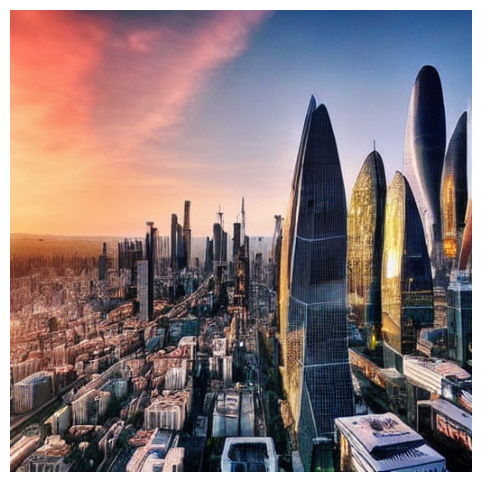

In [ ]:
import torch
import matplotlib.pyplot as plt
import time

print("Device:", device)
print("Testing image generation...")

start = time.time()

result = pipe(
    prompt="A beautiful futuristic city at sunset, realistic photography",
    num_inference_steps=15,
    guidance_scale=7.5,
    width=512,
    height=512
)

generated_image = result.images[0]

print("Image generated successfully!")
print("Time:", round(time.time() - start, 2), "seconds")

plt.figure(figsize=(6, 6))
plt.imshow(generated_image)
plt.axis("off")
plt.show()